# 02 — Exploratory Workload Analysis: Autocorrelation, Surge Regimes & Segment Heterogeneity
This notebook analyzes the four fleet-level targets (`fleet_avg_cpu`, `fleet_p95_max_cpu`, `fleet_busy_vm_fraction`, `active_vm_count`), computes exact training vs. full-trace autocorrelation functions (ACF), identifies peak and trough timestamps, and quantifies workload heterogeneity across `vm_category`, `virtual_core_bucket`, and the `13` pooled `vm_category | virtual_core_bucket` strata.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf
from IPython.display import Image, display

from cwfc.io import load_cpu_readings, load_vm_metadata
from cwfc.predict import build_fleet_targets
from cwfc.targets import split_train_holdout, build_segment_targets, split_raw_readings_train_holdout
from cwfc.models import assign_vm_segments

DATA_DIR = Path('../challenge_data')
readings = load_cpu_readings(DATA_DIR)
metadata = load_vm_metadata(DATA_DIR)
agg_df = build_fleet_targets(readings)
train_df, holdout_df = split_train_holdout(agg_df, n_holdout=24)

rows = []
for col in ['fleet_avg_cpu', 'fleet_p95_max_cpu', 'fleet_busy_vm_fraction', 'active_vm_count']:
    for split_name, df_part in [('Full (134)', agg_df), ('Train (110)', train_df), ('Holdout (24)', holdout_df)]:
        s = df_part[col]
        rows.append({
            'target': col, 'window': split_name,
            'mean': s.mean(), 'std': s.std(ddof=1),
            'min': s.min(), 't_min_s': int(df_part.loc[s.idxmin(), 'timestamp']),
            'max': s.max(), 't_max_s': int(df_part.loc[s.idxmax(), 'timestamp']),
        })
summary_targets = pd.DataFrame(rows)
display(summary_targets.round(4))

,target,window,mean,std,min,t_min_s,max,t_max_s
0,fleet_avg_cpu,Full (134),9.3881,0.1950,8.9836,33300,9.9122,16500
1,fleet_avg_cpu,Train (110),9.4141,0.1936,9.1116,32400,9.9122,16500
2,fleet_avg_cpu,Holdout (24),9.2690,0.1557,8.9836,33300,9.6360,37500
3,fleet_p95_max_cpu,Full (134),65.8265,2.5233,62.3492,27300,75.5846,16500
4,fleet_p95_max_cpu,Train (110),65.9279,2.7447,62.3492,27300,75.5846,16500
5,fleet_p95_max_cpu,Holdout (24),65.3616,0.9163,63.5003,33300,67.5502,37500
6,fleet_busy_vm_fraction,Full (134),0.0308,0.0037,0.0256,34800,0.0385,17100
7,fleet_busy_vm_fraction,Train (110),0.0306,0.0036,0.0262,27300,0.0385,17100
8,fleet_busy_vm_fraction,Holdout (24),0.0314,0.0043,0.0256,34800,0.0374,37500
9,active_vm_count,Full (134),10000.0000,0.0000,10000.0000,0,10000.0000,0


,target,window,lag_1 (5m),lag_2 (10m),lag_3 (15m),lag_6 (30m),lag_12 (60m),lag_24 (120m)
0,fleet_avg_cpu,Train (110 steps),0.6621,0.5946,0.6640,0.4498,0.3274,-0.0199
1,fleet_avg_cpu,Full (134 steps),0.6812,0.6177,0.7062,0.5205,0.4184,0.1084
2,fleet_p95_max_cpu,Train (110 steps),0.8306,0.7699,0.7000,0.5695,0.2336,-0.1166
3,fleet_p95_max_cpu,Full (134 steps),0.8201,0.7575,0.6937,0.5682,0.2434,-0.0980
4,fleet_busy_vm_fraction,Train (110 steps),0.4610,0.1733,0.1604,0.0094,0.4277,0.2741
5,fleet_busy_vm_fraction,Full (134 steps),0.4375,0.1842,0.2081,0.0073,0.3866,0.2532


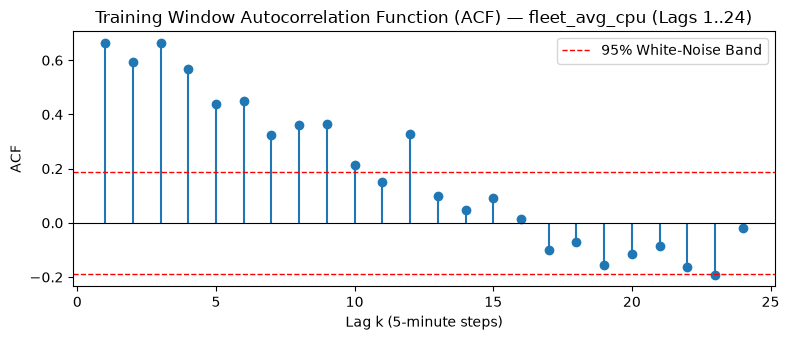

In [2]:
# Exact Autocorrelation (ACF) at lags 1, 2, 3, 6, 12, 24 (5m to 120m)
lags = [1, 2, 3, 6, 12, 24]
acf_rows = []
for col in ['fleet_avg_cpu', 'fleet_p95_max_cpu', 'fleet_busy_vm_fraction']:
    a_tr = acf(train_df[col], nlags=24, fft=False)
    a_full = acf(agg_df[col], nlags=24, fft=False)
    acf_rows.append({'target': col, 'window': 'Train (110 steps)', **{f'lag_{k} ({k*5}m)': a_tr[k] for k in lags}})
    acf_rows.append({'target': col, 'window': 'Full (134 steps)', **{f'lag_{k} ({k*5}m)': a_full[k] for k in lags}})
acf_table = pd.DataFrame(acf_rows)
display(acf_table.round(4))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.stem(range(1, 25), acf(train_df['fleet_avg_cpu'], nlags=24, fft=False)[1:], basefmt=' ')
ax.axhline(0, color='black', lw=0.8)
ax.axhline(1.96 / np.sqrt(len(train_df)), color='red', ls='--', lw=1, label='95% White-Noise Band')
ax.axhline(-1.96 / np.sqrt(len(train_df)), color='red', ls='--', lw=1)
ax.set_title('Training Window Autocorrelation Function (ACF) — fleet_avg_cpu (Lags 1..24)')
ax.set_xlabel('Lag k (5-minute steps)')
ax.set_ylabel('ACF')
ax.legend()
plt.tight_layout()
plt.show()

=== Segment Summary: vm_category ===


,vm_count,mean_cpu,std_cpu,min_cpu,max_cpu
vm_category,,,,,
Delay-insensitive,6180,8.2358,0.2057,7.9001,8.8776
Interactive,3091,11.4926,0.2626,10.9459,12.1489
Unknown,729,10.2332,0.6421,9.0355,11.5607


=== Segment Summary: virtual_core_bucket ===


,vm_count,mean_cpu,std_cpu,min_cpu,max_cpu
virtual_core_bucket,,,,,
2,7534,9.7249,0.2416,9.3424,10.4389
24,62,11.3975,0.3903,10.5247,12.6623
4,1908,7.9280,0.2212,7.4051,8.5646
8,486,9.7004,0.4199,8.7336,11.1332
>24,10,6.6176,1.9842,3.8189,14.7418


Total Pooled Bottom-Up Strata (min_segment_size=30): 13 strata


,vm_count
segment,
Delay-insensitive|2,4892
Interactive|2,2212
Delay-insensitive|4,1044
Interactive|4,653
Unknown|2,430
Unknown|4,211
Delay-insensitive|8,206
Interactive|8,199
Unknown|8,81


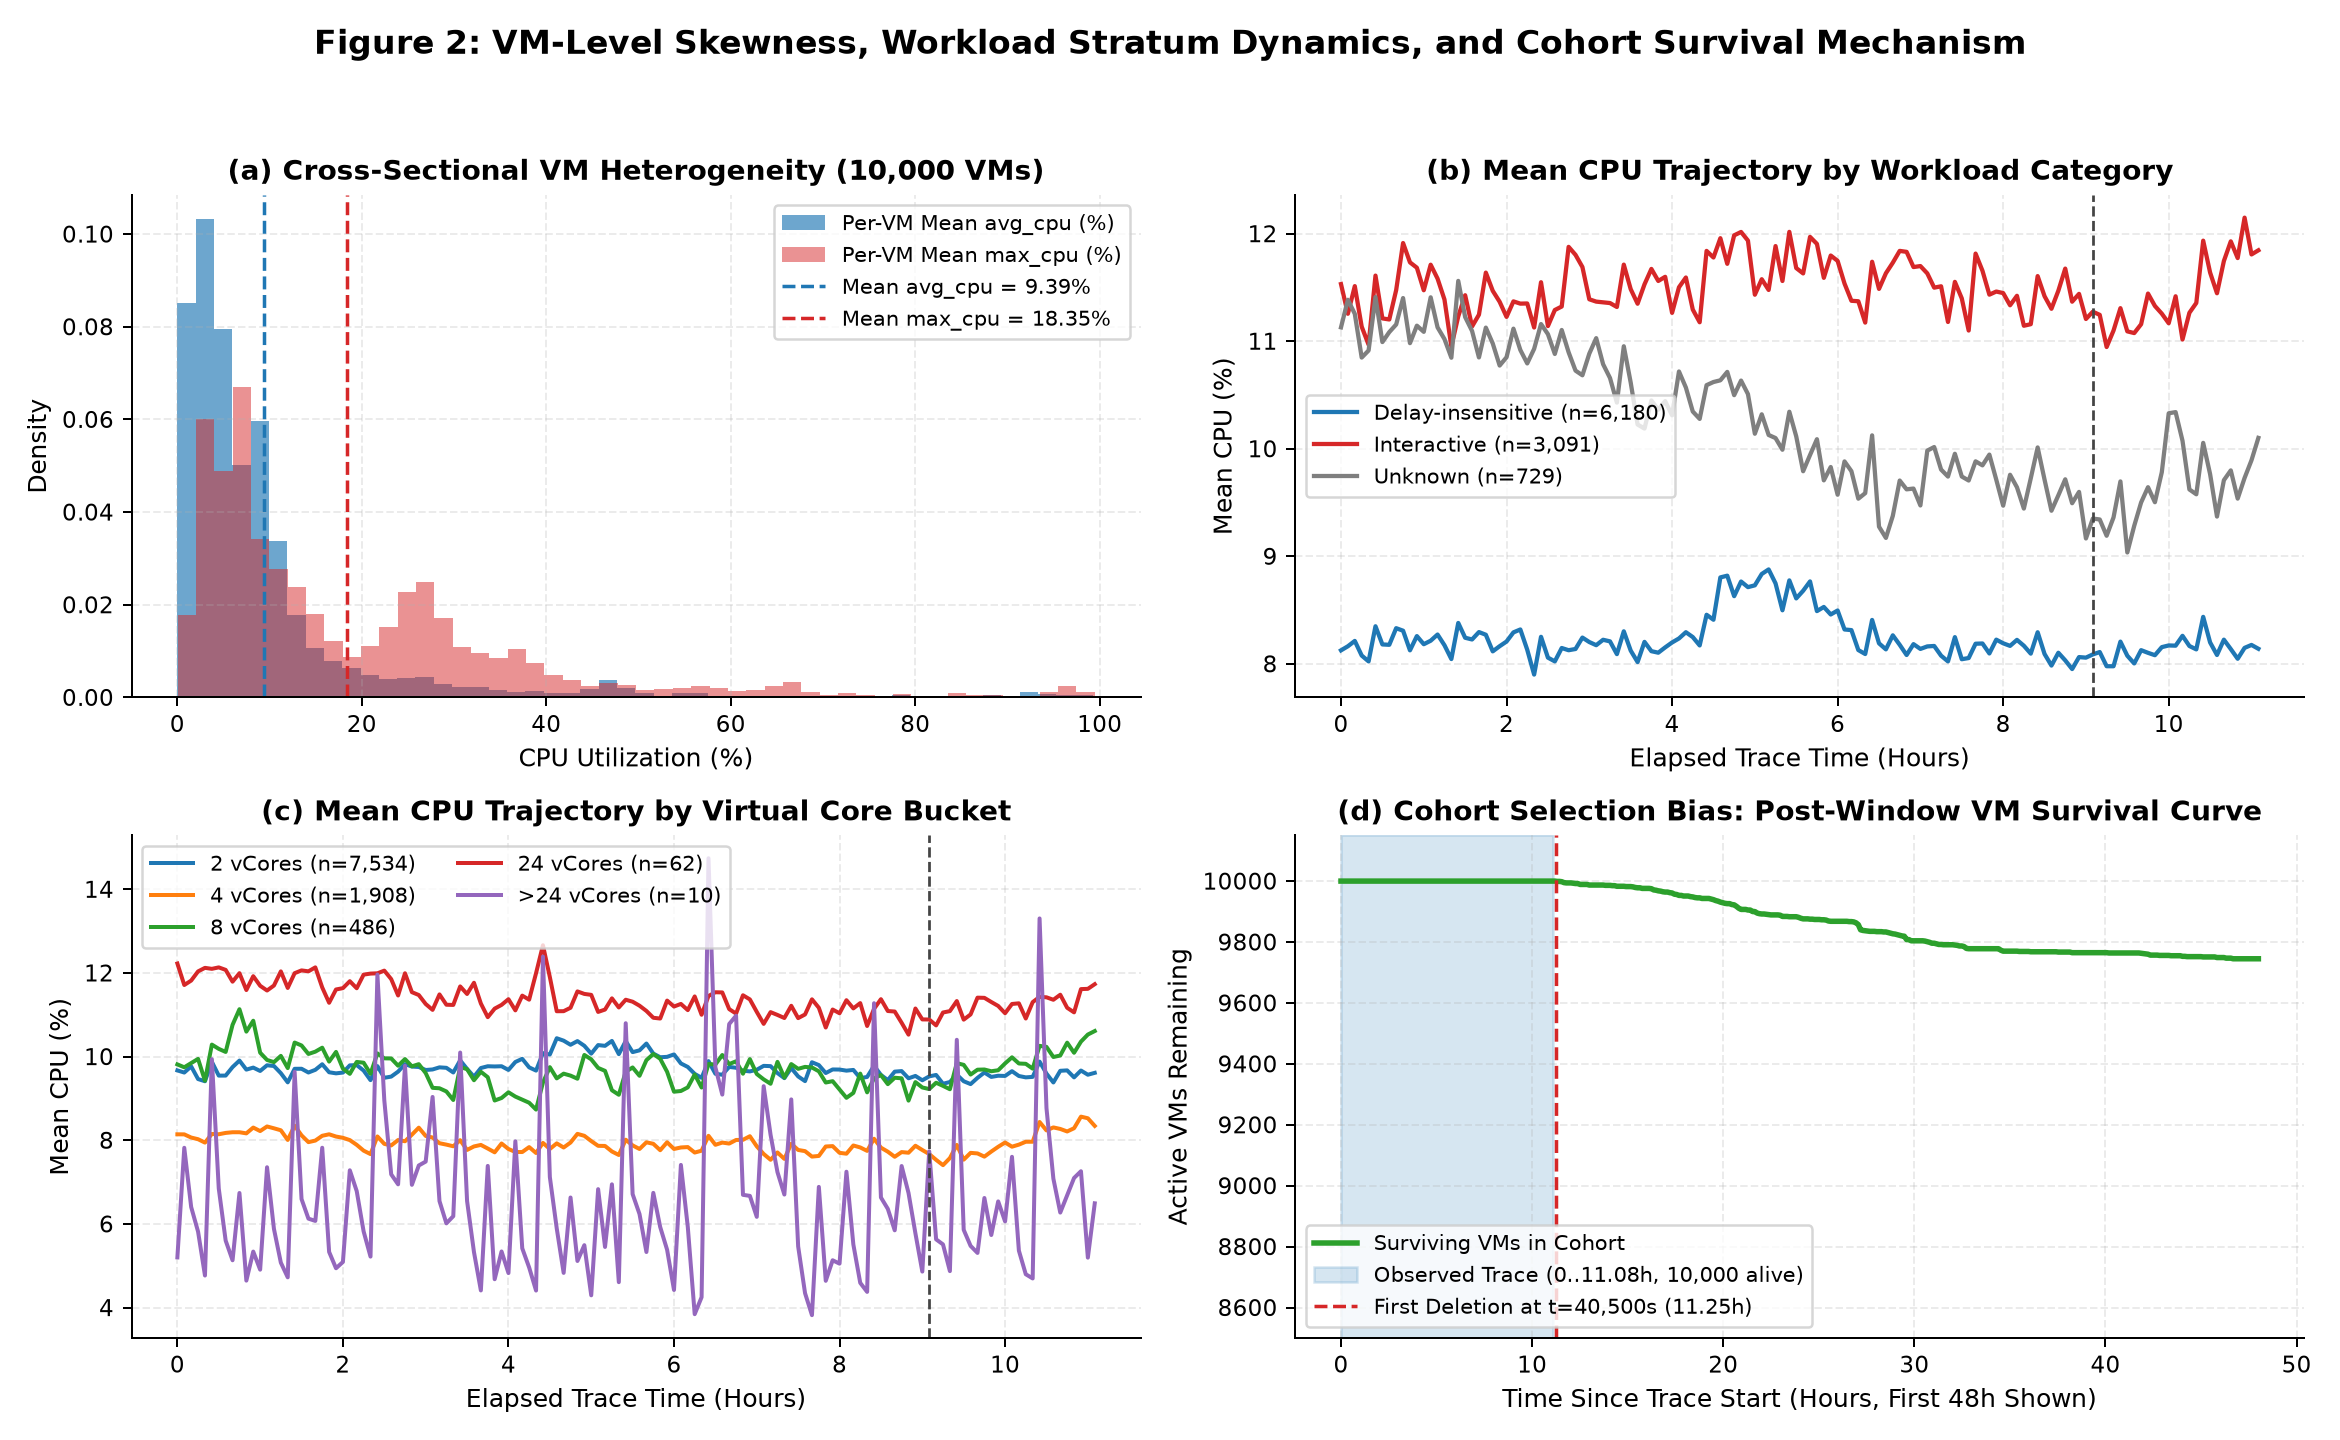

In [3]:
# Segment-level utilization statistics by vm_category and virtual_core_bucket
for seg_col in ['vm_category', 'virtual_core_bucket']:
    st = build_segment_targets(readings, metadata, seg_col)
    seg_stats = st.groupby(seg_col).agg(
        vm_count=('active_vm_count', 'first'),
        mean_cpu=('aggregate_cpu_utilization', 'mean'),
        std_cpu=('aggregate_cpu_utilization', 'std'),
        min_cpu=('aggregate_cpu_utilization', 'min'),
        max_cpu=('aggregate_cpu_utilization', 'max'),
    )
    print(f'=== Segment Summary: {seg_col} ===')
    display(seg_stats.round(4))

cpu_train, _, _ = split_raw_readings_train_holdout(readings, n_holdout=24)
strata = assign_vm_segments(cpu_train, metadata)
print(f'Total Pooled Bottom-Up Strata (min_segment_size=30): {strata.nunique()} strata')
display(strata.value_counts().rename('vm_count').to_frame())
display(Image(filename='../reports/figures/fig2_vm_heterogeneity_and_segments.png'))